### Part 1: Setup and look at the data

**Imports and settings**

For: Loads every tool the notebook needs, so nothing is imported later.

How: import lines bring in the libraries (PyTorch for the model, scikit-learn for scores, matplotlib/seaborn for graphs). os.makedirs("figures") creates the folder where all pictures will be saved. device becomes cuda if a GPU is available, otherwise cpu. It should print cuda.

In [1]:
!pip install -q kagglehub

import os, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import kagglehub

import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader, random_split

from sklearn.metrics import confusion_matrix, classification_report, roc_curve, auc
from sklearn.preprocessing import label_binarize
from sklearn.manifold import TSNE

sns.set_theme(style="whitegrid")
os.makedirs("figures", exist_ok=True)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using:", device)

Using: cpu


**Download the data**

For: Gets the brain MRI images into Colab.

How: kagglehub.dataset_download downloads the dataset and gives its folder location in path. The class names (glioma, meningioma, notumor, pituitary) are read from the folder names under Training and stored in classes, in alphabetical order.

In [2]:
path = kagglehub.dataset_download("masoudnickparvar/brain-tumor-mri-dataset")
classes = sorted(os.listdir(f"{path}/Training"))
print("Classes:", classes)

Using Colab cache for faster access to the 'brain-tumor-mri-dataset' dataset.
Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']


**See some images**

For: Lets you look at what an MRI scan and each tumour type look like.

How: For each class it picks 4 random images, draws them in a 4x4 grid (one row per class), and saves the picture to figures/p2_sample_images.png.

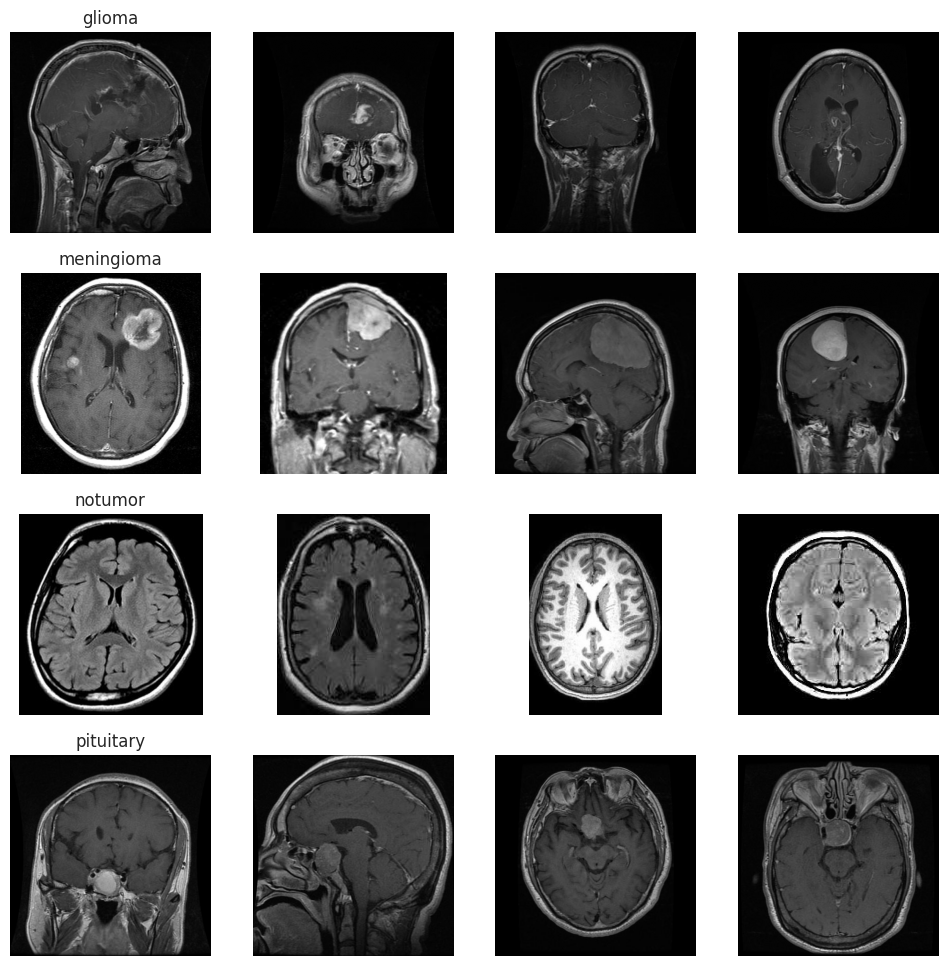

In [3]:
fig, axes = plt.subplots(4, 4, figsize=(12, 12))
for i, c in enumerate(classes):
    files = random.sample(os.listdir(f"{path}/Training/{c}"), 4)
    for j, f in enumerate(files):
        axes[i, j].imshow(Image.open(f"{path}/Training/{c}/{f}"), cmap="gray")
        axes[i, j].axis("off")
        if j == 0:
            axes[i, j].set_title(c)
plt.savefig("figures/p2_sample_images.png", dpi=200, bbox_inches="tight")
plt.show()

**Count images per class**

For: Shows whether the classes are balanced. If one class has far fewer images, the model may be worse at it.

How: Counts the files in each class folder for Training and Testing, puts them in a table, draws a bar chart, and saves it.

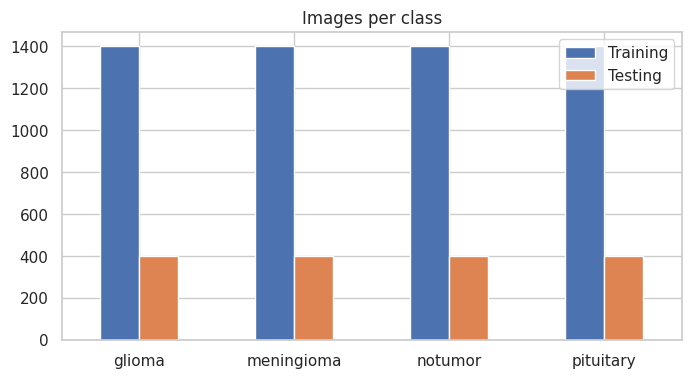

,Training,Testing
glioma,1400,400
meningioma,1400,400
notumor,1400,400
pituitary,1400,400


In [4]:
counts = pd.DataFrame({
    "Training": [len(os.listdir(f"{path}/Training/{c}")) for c in classes],
    "Testing":  [len(os.listdir(f"{path}/Testing/{c}")) for c in classes]
}, index=classes)

counts.plot(kind="bar", figsize=(8, 4), rot=0)
plt.title("Images per class")
plt.savefig("figures/p2_class_counts.png", dpi=200, bbox_inches="tight")
plt.show()
counts

###Part 2: Prepare the data and train

**Prepare the data**

For: Turns the image files into the format the model needs, and splits them into three groups.

How:
Grayscale(3) copies the one grey channel into three, because ResNet expects colour-shaped images.
Resize((224, 224)) makes every image the same size.
ToTensor turns images into numbers between 0 and 1.
Normalize rescales them the way the pretrained model expects.
ImageFolder reads the labels from the folder names.
80% of the Training folder is for training (the model learns), 20% is validation (checks progress while training), and the Testing folder is test (the final score, untouched until Cell 7).
DataLoader feeds the images in small batches (32 or 64 at a time).
mean and std are kept so later cells can turn normalised images back into viewable ones.

In [5]:
mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

tf = transforms.Compose([
    transforms.Grayscale(3),
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])

train_full = datasets.ImageFolder(f"{path}/Training", tf)
test_set = datasets.ImageFolder(f"{path}/Testing", tf)

n_val = int(0.2 * len(train_full))
train_set, val_set = random_split(train_full, [len(train_full) - n_val, n_val],
                                  generator=torch.Generator().manual_seed(0))

train_dl = DataLoader(train_set, batch_size=32, shuffle=True)
val_dl = DataLoader(val_set, batch_size=64)
test_dl = DataLoader(test_set, batch_size=64)
print("Train:", len(train_set), "| Validation:", len(val_set), "| Test:", len(test_set))

Train: 4480 | Validation: 1120 | Test: 1600


**Train the model**

For: Teaches the model to classify tumours. This is the slowest cell (about 8 minutes).

How:
It loads ResNet18, already trained on millions of everyday photos, and replaces its last layer with one that outputs 4 values, one per tumour class. This is called transfer learning.
Adam (the optimiser) adjusts the model’s numbers after each batch. CrossEntropyLoss measures how wrong the predictions are.
run_epoch makes one pass over the data. In training mode it also does loss.backward() (work out how to improve) and optimizer.step() (apply the improvement). In validation mode it only measures.
The loop runs 5 passes (epochs), saving loss and accuracy each time. The weights are saved to resnet18_baseline.pt, and the curves are drawn and saved.
How to read the curves: If training accuracy keeps rising but validation accuracy stops or drops, the model is memorising the training images (overfitting).

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 49.4MB/s]


Epoch 1: train acc 0.914 | validation acc 0.973
Epoch 2: train acc 0.986 | validation acc 0.948
Epoch 3: train acc 0.993 | validation acc 0.978
Epoch 4: train acc 0.995 | validation acc 0.973
Epoch 5: train acc 0.999 | validation acc 0.976


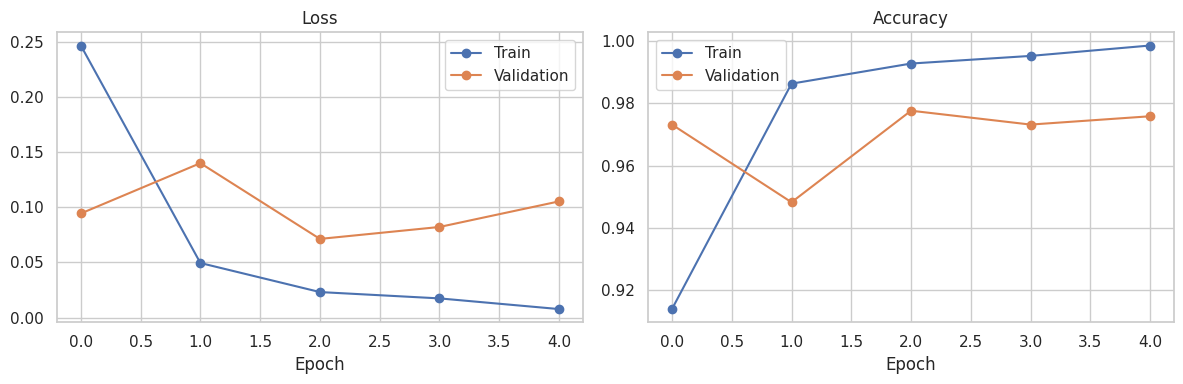

In [6]:
model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
model.fc = nn.Linear(model.fc.in_features, 4)
model = model.to(device)

optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)
loss_fn = nn.CrossEntropyLoss()

def run_epoch(loader, train):
    model.train(train)
    total_loss, correct = 0, 0
    for images, lab in loader:
        images, lab = images.to(device), lab.to(device)
        with torch.set_grad_enabled(train):
            outputs = model(images)
            loss = loss_fn(outputs, lab)
        if train:
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
        total_loss += loss.item() * len(lab)
        correct += (outputs.argmax(1) == lab).sum().item()
    n = len(loader.dataset)
    return total_loss / n, correct / n

history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
for epoch in range(5):
    tl, ta = run_epoch(train_dl, True)
    vl, va = run_epoch(val_dl, False)
    for key, value in zip(history, [tl, vl, ta, va]):
        history[key].append(value)
    print(f"Epoch {epoch+1}: train acc {ta:.3f} | validation acc {va:.3f}")

torch.save(model.state_dict(), "resnet18_baseline.pt")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history["train_loss"], marker="o", label="Train")
axes[0].plot(history["val_loss"], marker="o", label="Validation")
axes[0].set_title("Loss"); axes[0].set_xlabel("Epoch"); axes[0].legend()
axes[1].plot(history["train_acc"], marker="o", label="Train")
axes[1].plot(history["val_acc"], marker="o", label="Validation")
axes[1].set_title("Accuracy"); axes[1].set_xlabel("Epoch"); axes[1].legend()
plt.tight_layout()
plt.savefig("figures/p2_training_curves.png", dpi=200, bbox_inches="tight")
plt.show()

###Test results

**Predict on the test set**

For: Runs the trained model on images it has never seen. Cells 8 to 15 depend on its output.

How: model.eval() and torch.no_grad() switch off training behaviour. For each test batch, softmax turns the model’s outputs into probabilities that add up to 1. This makes three variables: probs (the probability for each class), labels (the true class), and preds (the class with the highest probability). It then prints the test accuracy.

In [7]:
model.eval()
all_probs, all_labels = [], []
with torch.no_grad():
    for images, lab in test_dl:
        out = model(images.to(device))
        all_probs.append(torch.softmax(out, 1).cpu().numpy())
        all_labels.append(lab.numpy())

probs = np.concatenate(all_probs)     # confidence for each class
labels = np.concatenate(all_labels)   # true class
preds = probs.argmax(1)               # predicted class
print("Test accuracy:", round((preds == labels).mean(), 4))

Test accuracy: 0.9331


**Class scores and confusion matrix**

For: Shows exactly where the model is right and wrong.

How: classification_report gives, per class, precision (when it says “glioma”, how often is it right?), recall (of all real gliomas, how many did it find?) and F1 (a mix of both). The confusion matrix counts images: rows are the true class, columns are the prediction. The diagonal is correct, and anything off the diagonal is a mix-up between two classes.

              precision    recall  f1-score   support

      glioma      0.988     0.790     0.878       400
  meningioma      0.891     0.965     0.927       400
     notumor      0.881     0.998     0.936       400
   pituitary      0.995     0.980     0.987       400

    accuracy                          0.933      1600
   macro avg      0.939     0.933     0.932      1600
weighted avg      0.939     0.933     0.932      1600



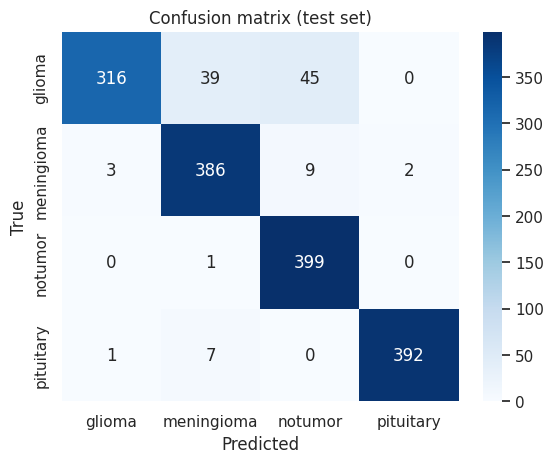

In [8]:
print(classification_report(labels, preds, target_names=classes, digits=3))

cm = confusion_matrix(labels, preds)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=classes, yticklabels=classes)
plt.xlabel("Predicted"); plt.ylabel("True")
plt.title("Confusion matrix (test set)")
plt.savefig("figures/p2_confusion.png", dpi=200, bbox_inches="tight")
plt.show()

**ROC curves**

For: Shows how well the model separates each tumour type from all the others, regardless of the cut-off used.

How: label_binarize turns the labels into four yes/no columns, one per class. For each class, roc_curve compares the model’s probability against yes/no. A curve close to the top-left corner is better, and the AUC number in the legend is 1.0 for perfect.

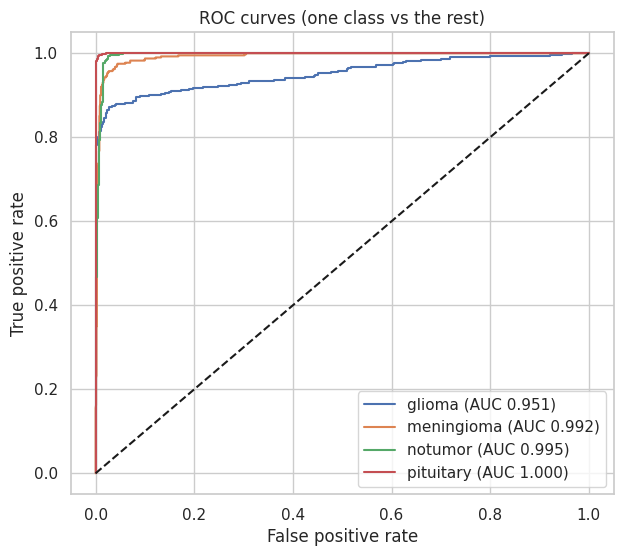

In [9]:
Y = label_binarize(labels, classes=[0, 1, 2, 3])
plt.figure(figsize=(7, 6))
for i, c in enumerate(classes):
    fpr, tpr, _ = roc_curve(Y[:, i], probs[:, i])
    plt.plot(fpr, tpr, label=f"{c} (AUC {auc(fpr, tpr):.3f})")
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
plt.title("ROC curves (one class vs the rest)")
plt.legend()
plt.savefig("figures/p2_roc.png", dpi=200, bbox_inches="tight")
plt.show()

###Explain and test the model

**Grad-CAM**

For: Shows where the model looked when it made a prediction.

How: register_forward_hook lets the code grab the output of the last convolutional block (layer4) during a prediction. It then runs backward() from the predicted class to see which parts of that output mattered most. Those importance values are averaged and used to weight the feature maps, and the result is stretched to 224x224 and scaled to 0 to 1. It is drawn as a red-to-blue overlay on the scan, using the first test image of each class. try/finally makes sure the hook is always removed afterwards.

Caution: It shows where the model looked, not why it decided. Describe only what you see in the figure.

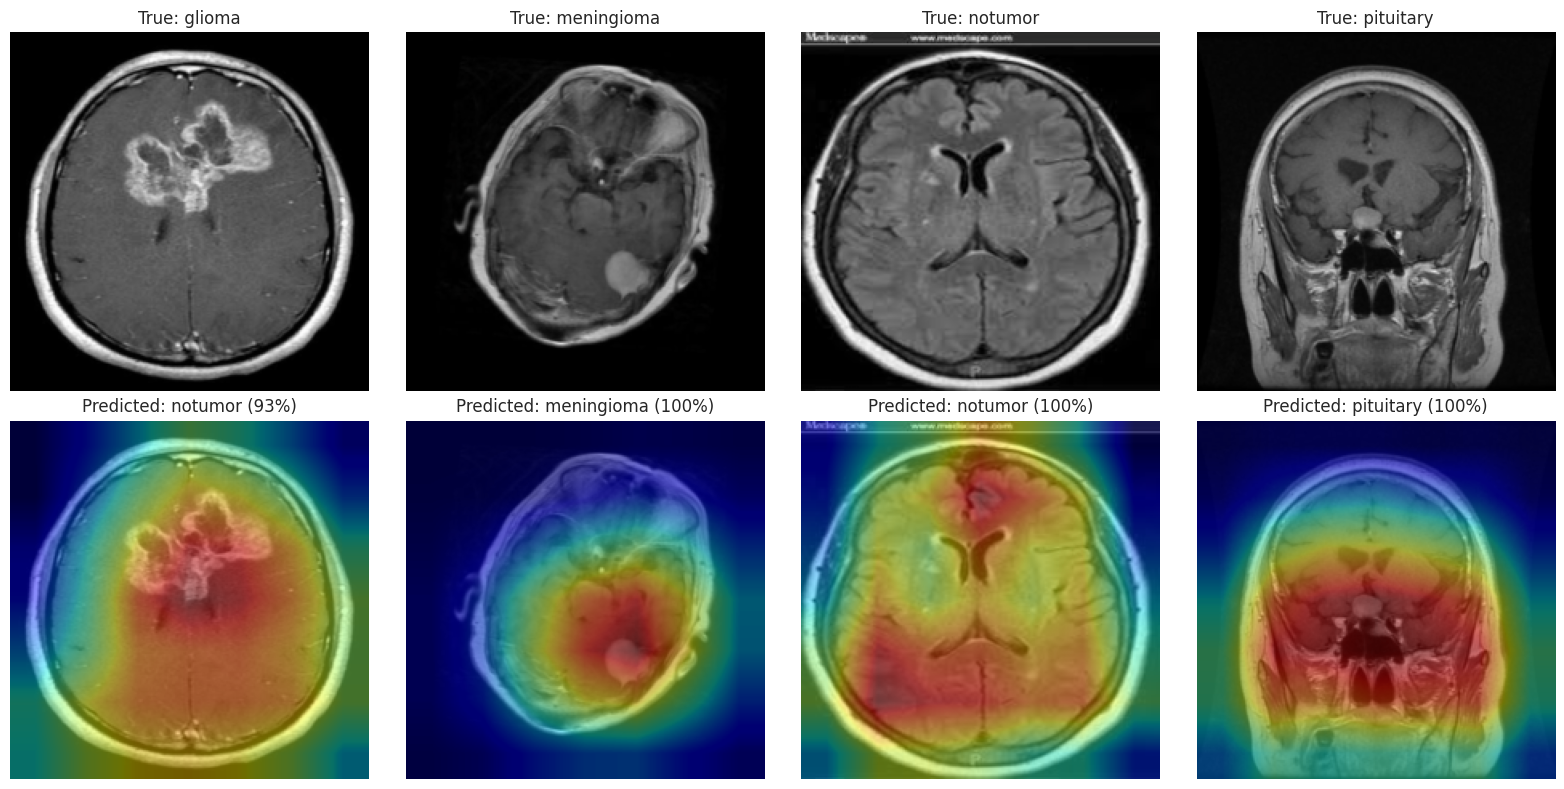

In [10]:
def gradcam(image):
    model.eval()
    acts, grads = [], []

    def save_acts(module, inp, out):
        acts.append(out)
        out.register_hook(lambda g: grads.append(g))

    hook = model.layer4[-1].register_forward_hook(save_acts)
    try:
        out = model(image.unsqueeze(0).to(device))
        pred = out.argmax(1).item()
        conf = torch.softmax(out, 1)[0, pred].item()
        model.zero_grad()
        out[0, pred].backward()
    finally:
        hook.remove()

    weights = grads[0].mean(dim=(2, 3), keepdim=True)
    cam = F.relu((weights * acts[0]).sum(1, keepdim=True))
    cam = F.interpolate(cam, size=(224, 224), mode="bilinear")[0, 0].detach().cpu().numpy()
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
    return cam, pred, conf

targets = np.array(test_set.targets)
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for i, c in enumerate(classes):
    idx = np.where(targets == i)[0][0]          # first test image of this class
    image, _ = test_set[idx]
    cam, pred, conf = gradcam(image)
    show = (image * std + mean).permute(1, 2, 0).clamp(0, 1).numpy()
    axes[0, i].imshow(show)
    axes[0, i].set_title(f"True: {c}")
    axes[1, i].imshow(show)
    axes[1, i].imshow(cam, cmap="jet", alpha=0.45)
    axes[1, i].set_title(f"Predicted: {classes[pred]} ({conf:.0%})")
for a in axes.ravel():
    a.axis("off")
plt.tight_layout()
plt.savefig("figures/p2_gradcam.png", dpi=200, bbox_inches="tight")
plt.show()

**Mistakes gallery**

For: Lets you look at the images the model got wrong.

How: np.where(preds != labels) finds the wrong predictions, and the first 8 are shown with their true class, predicted class and the model’s confidence. If there are fewer than 8, the empty boxes stay blank.

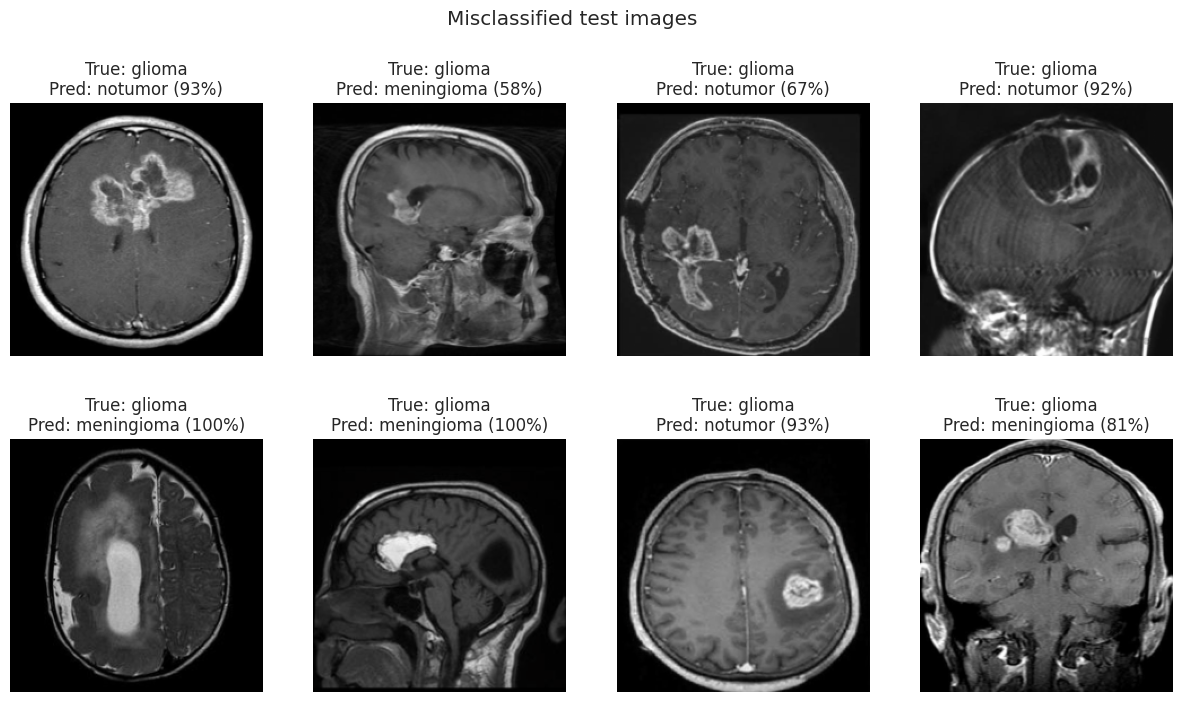

In [11]:
wrong = np.where(preds != labels)[0][:8]
fig, axes = plt.subplots(2, 4, figsize=(15, 8))
for a in axes.ravel():
    a.axis("off")
for a, idx in zip(axes.ravel(), wrong):
    image, _ = test_set[idx]
    a.imshow((image * std + mean).permute(1, 2, 0).clamp(0, 1).numpy())
    a.set_title(f"True: {classes[labels[idx]]}\nPred: {classes[preds[idx]]} ({probs[idx].max():.0%})")
plt.suptitle("Misclassified test images")
plt.savefig("figures/p2_mistakes.png", dpi=200, bbox_inches="tight")
plt.show()

**Robustness to missing image regions**

For: Tests what happens when parts of the image are missing. This links to Project 1.

How: hide_patches makes a random 14x14 grid of 1s (keep) and 0s (hide) and enlarges it by 16 times to 224x224, so each block is a 16x16 pixel patch. It multiplies the image by that grid, so hidden patches turn mid-grey. The loop hides 0% to 70% of each test image, measures accuracy and average confidence at each level, and plots both. A second figure shows what the hidden images look like. torch.manual_seed(0) makes the patches repeatable.

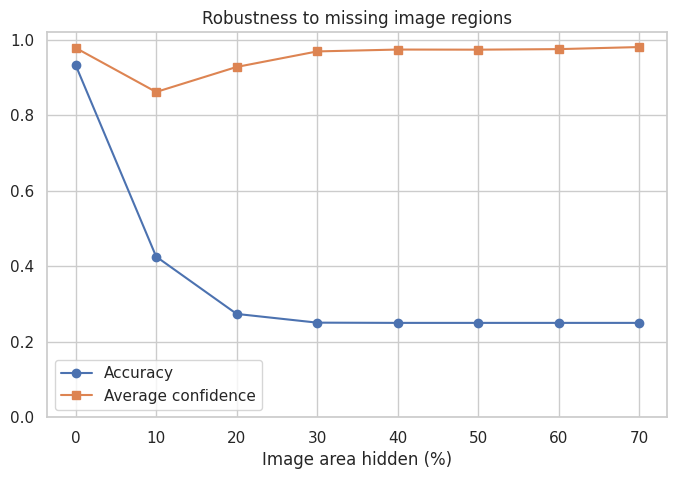

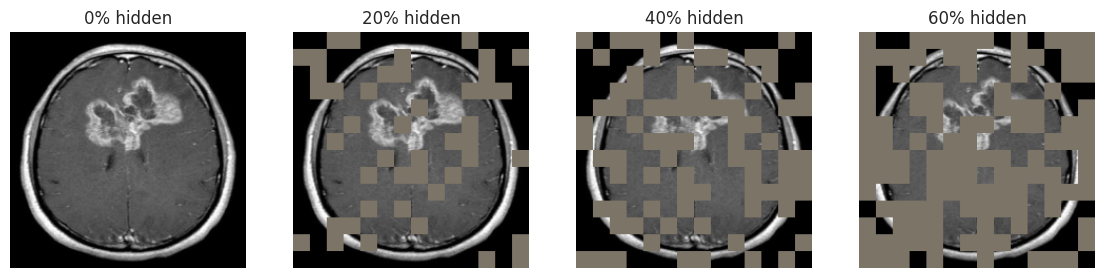

In [12]:
torch.manual_seed(0)

def hide_patches(images, fraction):
    grid = (torch.rand(images.shape[0], 1, 14, 14) >= fraction).float()
    mask = F.interpolate(grid, scale_factor=16, mode="nearest")   # 14 x 14 grid -> 224 x 224
    return images * mask

fracs = [0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7]
accs, confs = [], []
model.eval()
for fr in fracs:
    correct, conf_sum = 0, 0
    with torch.no_grad():
        for images, lab in test_dl:
            p = torch.softmax(model(hide_patches(images, fr).to(device)), 1).cpu()
            correct += (p.argmax(1) == lab).sum().item()
            conf_sum += p.max(1).values.sum().item()
    accs.append(correct / len(test_set))
    confs.append(conf_sum / len(test_set))

# Graph 1: accuracy and confidence vs % hidden
plt.figure(figsize=(8, 5))
plt.plot([f * 100 for f in fracs], accs, marker="o", label="Accuracy")
plt.plot([f * 100 for f in fracs], confs, marker="s", label="Average confidence")
plt.xlabel("Image area hidden (%)"); plt.ylim(0, 1.02)
plt.title("Robustness to missing image regions")
plt.legend()
plt.savefig("figures/p2_robustness.png", dpi=200, bbox_inches="tight")
plt.show()

# Graph 2: what the hidden images look like
image, _ = test_set[0]
fig, axes = plt.subplots(1, 4, figsize=(14, 4))
for a, fr in zip(axes, [0, 0.2, 0.4, 0.6]):
    shown = hide_patches(image.unsqueeze(0), fr)[0] * std + mean
    a.imshow(shown.permute(1, 2, 0).clamp(0, 1).numpy())
    a.set_title(f"{int(fr*100)}% hidden"); a.axis("off")
plt.savefig("figures/p2_robustness_examples.png", dpi=200, bbox_inches="tight")
plt.show()

**Calibration**

For: Checks whether the model’s confidence can be trusted. If it says “90% sure”, it should be right about 90% of the time.

How: confidence is the highest probability for each image. The images are grouped into 10 confidence bands, and for each band the code compares the average confidence with the actual accuracy. ECE (Expected Calibration Error) is the weighted average of those gaps, and lower is better. The left graph (reliability diagram) should follow the dashed diagonal. The right graph compares the confidence of correct and wrong predictions, and wrong ones should sit lower.

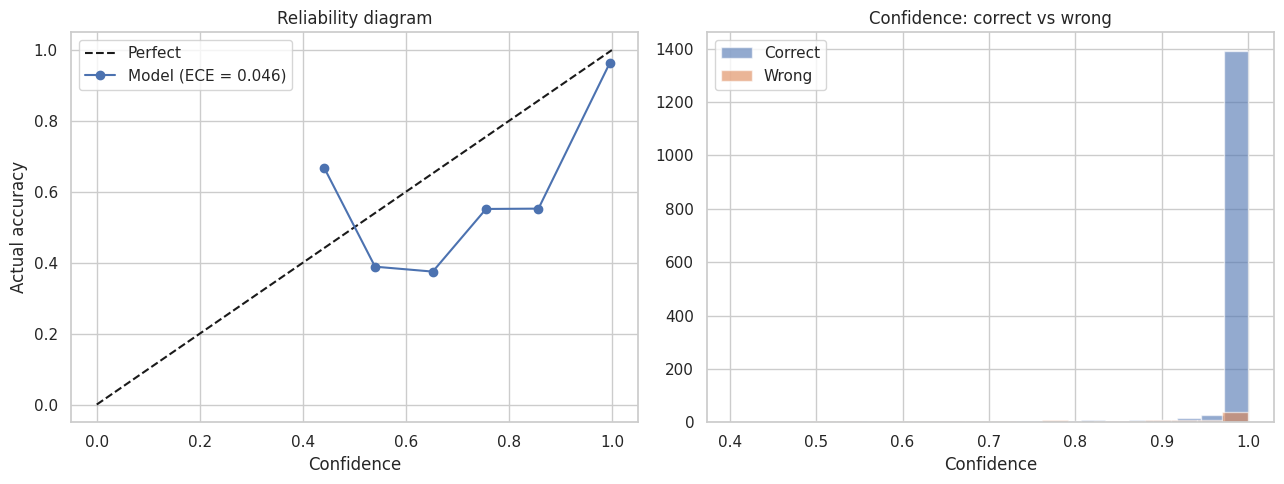

In [13]:
confidence = probs.max(1)
correct = (preds == labels)

bins = np.linspace(0, 1, 11)
bin_conf, bin_acc, ece = [], [], 0
for low, high in zip(bins[:-1], bins[1:]):
    in_bin = (confidence > low) & (confidence <= high)
    if in_bin.sum() > 0:
        bin_conf.append(confidence[in_bin].mean())
        bin_acc.append(correct[in_bin].mean())
        ece += in_bin.mean() * abs(confidence[in_bin].mean() - correct[in_bin].mean())

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].plot([0, 1], [0, 1], "k--", label="Perfect")
axes[0].plot(bin_conf, bin_acc, marker="o", label=f"Model (ECE = {ece:.3f})")
axes[0].set_xlabel("Confidence"); axes[0].set_ylabel("Actual accuracy")
axes[0].set_title("Reliability diagram"); axes[0].legend()
axes[1].hist(confidence[correct], bins=20, alpha=0.6, label="Correct")
axes[1].hist(confidence[~correct], bins=20, alpha=0.6, label="Wrong")
axes[1].set_xlabel("Confidence"); axes[1].set_title("Confidence: correct vs wrong")
axes[1].legend()
plt.tight_layout()
plt.savefig("figures/p2_calibration.png", dpi=200, bbox_inches="tight")
plt.show()

**t-SNE**

For: Gives a picture of what the model has learned.

How: A hook on avgpool collects 512 numbers describing each test image. TSNE squashes those 512 numbers down to 2 so they can be plotted. Each dot is an image, coloured by its true class. Clearly separate clusters mean the model learned distinct classes.

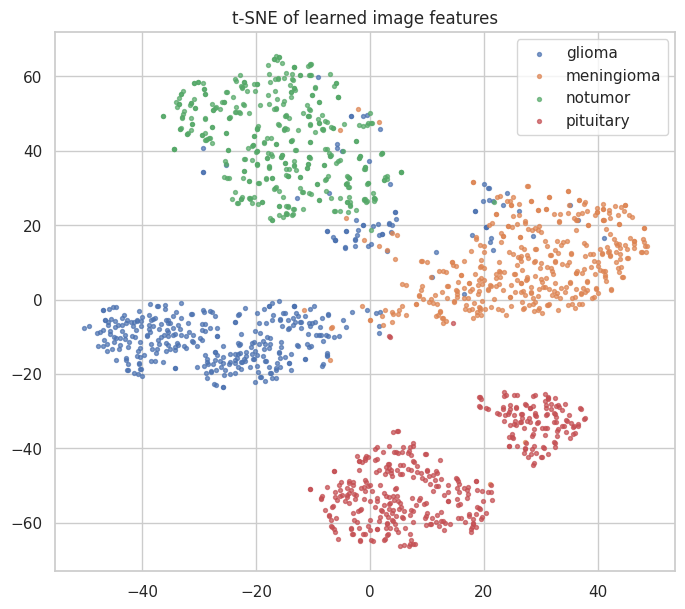

In [14]:
features = []
hook = model.avgpool.register_forward_hook(
    lambda m, i, o: features.append(o.flatten(1).detach().cpu()))
model.eval()
with torch.no_grad():
    for images, _ in test_dl:
        model(images.to(device))
hook.remove()

Z = TSNE(n_components=2, random_state=0, init="pca").fit_transform(torch.cat(features).numpy())

plt.figure(figsize=(8, 7))
for i, c in enumerate(classes):
    plt.scatter(Z[labels == i, 0], Z[labels == i, 1], s=8, alpha=0.7, label=c)
plt.legend(); plt.title("t-SNE of learned image features")
plt.savefig("figures/p2_tsne.png", dpi=200, bbox_inches="tight")
plt.show()

###Part 5: Final numbers

Print the final numbers

For: Collects everything the README and report need in one place.

How: It prints the test accuracy, ECE and the full class report. To find the most common mistake, it copies the confusion matrix, sets the diagonal to zero, and finds the biggest remaining value. It then prints accuracy and confidence at each hidden-image level.

In [15]:
print("Test accuracy:", round((preds == labels).mean(), 4))
print("ECE:", round(ece, 3))
print(classification_report(labels, preds, target_names=classes, digits=3))

off = cm.copy()
np.fill_diagonal(off, 0)
i, j = np.unravel_index(off.argmax(), off.shape)
print(f"Most common mistake: true {classes[i]} predicted as {classes[j]} ({off[i, j]} images)")

print("\nImage area hidden -> accuracy, average confidence")
for fr, a, c in zip(fracs, accs, confs):
    print(f"{int(fr*100):>3}% -> {a:.3f}, {c:.3f}")

Test accuracy: 0.9331
ECE: 0.046
              precision    recall  f1-score   support

      glioma      0.988     0.790     0.878       400
  meningioma      0.891     0.965     0.927       400
     notumor      0.881     0.998     0.936       400
   pituitary      0.995     0.980     0.987       400

    accuracy                          0.933      1600
   macro avg      0.939     0.933     0.932      1600
weighted avg      0.939     0.933     0.932      1600

Most common mistake: true glioma predicted as notumor (45 images)

Image area hidden -> accuracy, average confidence
  0% -> 0.933, 0.979
 10% -> 0.426, 0.862
 20% -> 0.274, 0.928
 30% -> 0.251, 0.969
 40% -> 0.250, 0.974
 50% -> 0.250, 0.974
 60% -> 0.250, 0.975
 70% -> 0.250, 0.981


In [16]:
print("Working folder:", os.getcwd())
print(sorted(os.listdir("figures")))

Working folder: /content
['p2_calibration.png', 'p2_class_counts.png', 'p2_confusion.png', 'p2_gradcam.png', 'p2_mistakes.png', 'p2_robustness.png', 'p2_robustness_examples.png', 'p2_roc.png', 'p2_sample_images.png', 'p2_training_curves.png', 'p2_tsne.png']


In [17]:
!zip -r figures.zip figures
from google.colab import files
files.download("figures.zip")

  adding: figures/ (stored 0%)
  adding: figures/p2_confusion.png (deflated 11%)
  adding: figures/p2_class_counts.png (deflated 24%)
  adding: figures/p2_gradcam.png (deflated 6%)
  adding: figures/p2_tsne.png (deflated 6%)
  adding: figures/p2_training_curves.png (deflated 11%)
  adding: figures/p2_robustness.png (deflated 13%)
  adding: figures/p2_sample_images.png (deflated 2%)
  adding: figures/p2_robustness_examples.png (deflated 4%)
  adding: figures/p2_roc.png (deflated 14%)
  adding: figures/p2_calibration.png (deflated 15%)
  adding: figures/p2_mistakes.png (deflated 2%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>